In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir()) / "src"))
from report_utils import *

ROOT = project_root()
DATA = ROOT / "data" / "processed"
FIG, TAB = output_dirs(ROOT)
set_style()

NAMES = ["train_clean", "train_attacked", "val", "test_seen", "test_unseen",
         "test_reppen", "test_seen_attacks", "test_heldout_attacks"]
sets = {n: pd.read_parquet(DATA / f"{n}.parquet") for n in NAMES}

In [2]:
sizes = pd.DataFrame({
    "Set": NAMES,
    "Texts": [len(sets[n]) for n in NAMES],
    "AI": [int(sets[n]["label"].sum()) for n in NAMES],
    "Human": [int((sets[n]["label"] == 0).sum()) for n in NAMES],
    "Generators": [sets[n].loc[sets[n]["label"] == 1, "model"].nunique() for n in NAMES],
    "Attacks": [sets[n]["attack"].nunique() if n.endswith("attacks") or n == "train_attacked" else 0
                for n in NAMES],
}).set_index("Set")
save_table(sizes, "split_sizes", TAB, "Experiment sets built from RAID (balanced per source document)")
sizes

saved tables/split_sizes.csv and .tex


,Texts,AI,Human,Generators,Attacks
Set,,,,,
train_clean,18718,9359,9359,7,0
train_attacked,18718,9359,9359,7,6
val,4012,2006,2006,7,0
test_seen,4012,2006,2006,7,0
test_unseen,4012,2006,2006,4,0
test_reppen,4012,2006,2006,3,0
test_seen_attacks,24072,12036,12036,7,6
test_heldout_attacks,20060,10030,10030,7,5


In [3]:
split_ids = {
    "train": set(sets["train_clean"]["source_id"]) | set(sets["train_attacked"]["source_id"]),
    "val": set(sets["val"]["source_id"]),
    "test": set().union(*(set(sets[n]["source_id"]) for n in NAMES if n.startswith("test"))),
}
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    overlap = len(split_ids[a] & split_ids[b])
    print(f"{a:>5} ∩ {b:<5}: {overlap} shared source documents")
    assert overlap == 0, "Leakage between splits!"
print("\nNo source document appears in more than one split.")

train ∩ val  : 0 shared source documents
train ∩ test : 0 shared source documents
  val ∩ test : 0 shared source documents

No source document appears in more than one split.


In [4]:
tr = sets["train_clean"].copy()
tr["words"] = word_count(tr["text"])
tr["rep_ratio"] = tr["text"].map(repeated_word_ratio)
tr["class"] = np.where(tr["label"] == 1, "AI", "Human")

by_class = tr.groupby("class").agg(
    median_words=("words", "median"),
    q1_words=("words", lambda s: s.quantile(0.25)),
    q3_words=("words", lambda s: s.quantile(0.75)),
    median_rep_ratio=("rep_ratio", "median"),
).round(3)
save_table(by_class, "length_by_class", TAB, "Text length (words) and repeated-word ratio by class, training set")
by_class

saved tables/length_by_class.csv and .tex


,median_words,q1_words,q3_words,median_rep_ratio
class,,,,
AI,221.0,138.0,329.0,0.420
Human,227.0,180.0,292.0,0.381


saved figures/length_distribution.pdf and .png


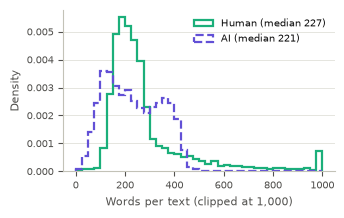

In [5]:
fig, ax = plt.subplots(figsize=(COL_W, 2.1))
bins = np.arange(0, 1001, 25)
for (name, colour, style) in [("Human", PAIR[0], "-"), ("AI", PAIR[1], "--")]:
    w = tr.loc[tr["class"] == name, "words"].clip(upper=1000)
    ax.hist(w, bins=bins, histtype="step", color=colour, linestyle=style, linewidth=1.6,
            density=True, label=f"{name} (median {int(w.median())})")
ax.set_xlabel("Words per text (clipped at 1,000)")
ax.set_ylabel("Density")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right")
save_fig(fig, "length_distribution", FIG)
plt.show()

In [6]:
by_domain = (tr.pivot_table(index="domain", columns="class", values="words", aggfunc="median")
             .astype(int).rename(columns=lambda c: f"Median words ({c})"))
by_domain["Texts"] = tr.groupby("domain").size()
save_table(by_domain, "length_by_domain", TAB, "Median text length by domain and class, training set")
by_domain

saved tables/length_by_domain.csv and .tex


class,Median words (AI),Median words (Human),Texts
domain,,,
abstracts,134,171,2472
books,260,261,2494
news,289,329,2492
poetry,174,243,2480
recipes,225,269,2480
reddit,180,166,2490
reviews,245,275,1320
wiki,290,193,2490


In [7]:
ai_all = pd.concat([sets[n][sets[n]["label"] == 1]
                    for n in ["train_clean", "test_unseen"]], ignore_index=True)
ai_all["words"] = word_count(ai_all["text"])
ai_all["rep_ratio"] = ai_all["text"].map(repeated_word_ratio)
by_gen = ai_all.groupby("model").agg(
    texts=("text", "size"), median_words=("words", "median"),
    median_rep_ratio=("rep_ratio", "median")).round(3)
by_gen.insert(0, "type", by_gen.index.map(GENERATOR_TYPE))
by_gen.insert(1, "split", ["held-out" if g in HELDOUT_GENERATORS else "seen" for g in by_gen.index])
by_gen = by_gen.sort_values(["split", "type"])
save_table(by_gen, "generators", TAB, "AI text by generator (training set and held-out test set)")
by_gen

saved tables/generators.csv and .tex


,type,split,texts,median_words,median_rep_ratio
model,,,,,
mpt,base,held-out,504,363.0,0.544
gpt4,chat,held-out,523,292.0,0.391
llama-chat,chat,held-out,493,285.0,0.449
mpt-chat,chat,held-out,486,143.0,0.362
cohere,base,seen,1279,210.0,0.400
gpt2,base,seen,1339,360.0,0.595
gpt3,base,seen,1371,117.0,0.365
mistral,base,seen,1311,315.0,0.527
chatgpt,chat,seen,1335,272.0,0.406


In [8]:
orig = sets["test_seen"].set_index("id")["text"]
att = pd.concat([sets["test_seen_attacks"], sets["test_heldout_attacks"]], ignore_index=True)
att["orig_text"] = att["adv_source_id"].map(orig)
att["words_ratio"] = word_count(att["text"]) / word_count(att["orig_text"])
att["chars_ratio"] = att["text"].str.len() / att["orig_text"].str.len()
att["non_ascii"] = att["text"].str.contains(r"[^\x00-\x7F]", regex=True)
att["changed"] = att["text"] != att["orig_text"]

attack_effect = att.groupby("attack").agg(
    seen_in_training=("attack", lambda s: s.iloc[0] in SEEN_ATTACKS),
    texts_changed=("changed", "mean"),
    median_word_ratio=("words_ratio", "median"),
    median_char_ratio=("chars_ratio", "median"),
    with_non_ascii=("non_ascii", "mean"),
).round(3).sort_values("seen_in_training", ascending=False)
save_table(attack_effect, "attack_effects", TAB, "How each attack changes the text (test set, relative to the original)")
attack_effect

saved tables/attack_effects.csv and .tex


,seen_in_training,texts_changed,median_word_ratio,median_char_ratio,with_non_ascii
attack,,,,,
alternative_spelling,True,0.618,1.000,1.000,0.234
article_deletion,True,0.977,0.961,0.978,0.234
number,True,0.506,1.000,1.000,0.234
paraphrase,True,1.000,0.907,0.881,0.490
perplexity_misspelling,True,0.737,1.000,1.000,0.234
synonym,True,0.999,1.000,0.998,0.241
homoglyph,False,1.000,1.000,1.000,1.000
insert_paragraphs,False,0.958,1.000,1.006,0.234
upper_lower,False,0.999,1.000,1.000,0.234


In [9]:
# One short example per attack. repr() makes invisible characters visible
example = att[att["label"] == 1].groupby("attack").head(1)
for _, r in example.iterrows():
    print(f"=== {r['attack']} ===")
    print("original:", repr(r["orig_text"][:160]))
    print("attacked:", repr(r["text"][:160]), "\n")

=== paraphrase ===
original: 'The paper examines Conformal Parameterizations of slices of flat Kasner spacetimes in the presence of a cosmological constant. These spacetimes are described by'
attacked: 'This paper examines the problem of the conformal epsilon of a section of the flat Kasner universe with a cosmological constant. This section is described by a s' 

=== article_deletion ===
original: 'Arsenal has been granted permission to move forward to the next stage of the competition, with a draw in the second leg of their Champions League tie against Ro'
attacked: 'Arsenal has been granted permission to move forward to next stage of competition, with draw in the second leg of their Champions League tie against Roma seeing ' 

=== number ===
original: "Sure! Here's a plot summary of an untitled novel:\n\nIn the small, quiet town of Bright River, a young man named Adam is having a hard time adjusting to his new l"
attacked: "Sure! Here's a plot summary of an untitled novel:\n\nIn the